# ARTI404 – Image Processing
## Lab 5: Spatial Filtering – Smoothing and Sharpening

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Task 1: 7x7 Box Filter

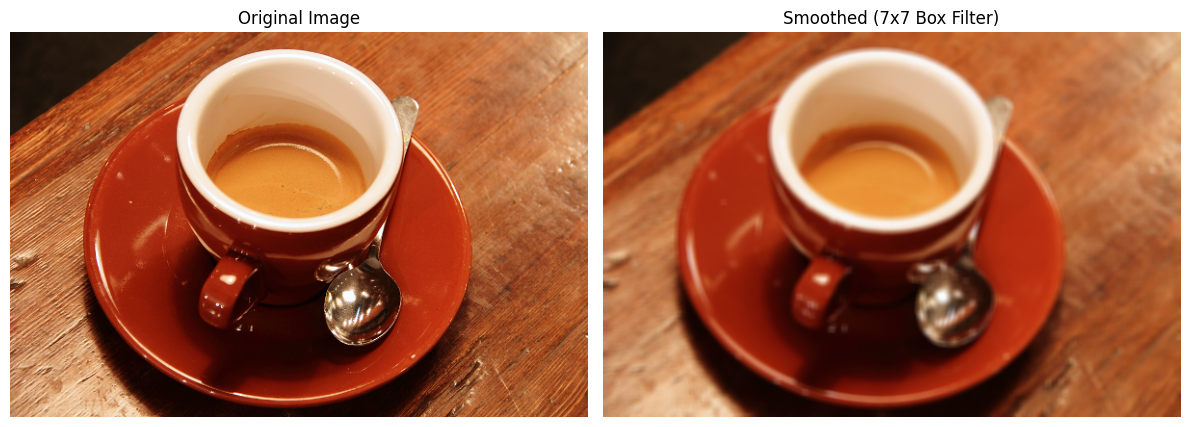

In [2]:
# Read the image
image = cv2.imread('images/coffee.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 7x7 box filter kernel (all weights = 1/49)
kernel = np.ones((7, 7), np.float32) / 49

# Convolve the image with the box filter
smoothed = cv2.filter2D(image, -1, kernel)

# Plot original and smoothed images side by side
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(smoothed)
ax[1].set_title("Smoothed (7x7 Box Filter)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## Task 2: 5x5 and 21x21 Gaussian Filters

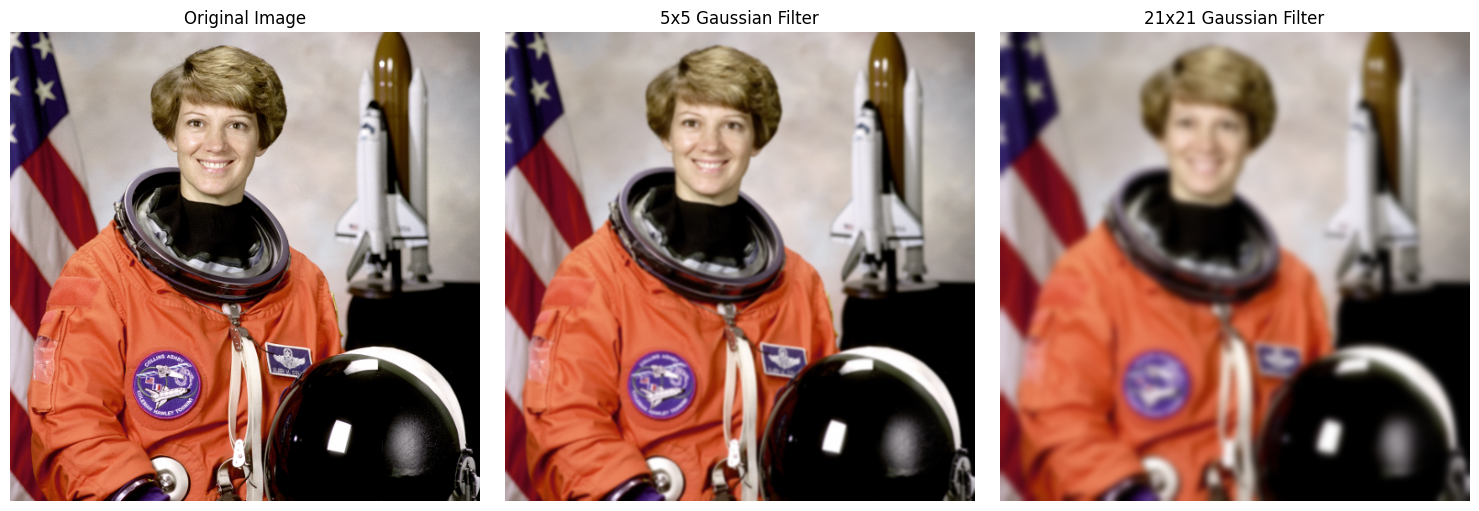

In [3]:
# Read the image
image = cv2.imread('images/astronaut.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply 5x5 and 21x21 Gaussian filters (sigma computed from kernel size)
gauss_5 = cv2.GaussianBlur(image, (5, 5), 0)
gauss_21 = cv2.GaussianBlur(image, (21, 21), 0)

# Plot the three images side by side
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(gauss_5)
ax[1].set_title("5x5 Gaussian Filter")
ax[1].axis("off")
ax[2].imshow(gauss_21)
ax[2].set_title("21x21 Gaussian Filter")
ax[2].axis("off")
plt.tight_layout()
plt.show()

## Task 3: Sharpening with a 3x3 Laplacian Filter

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-8.444751e-09..1.0].


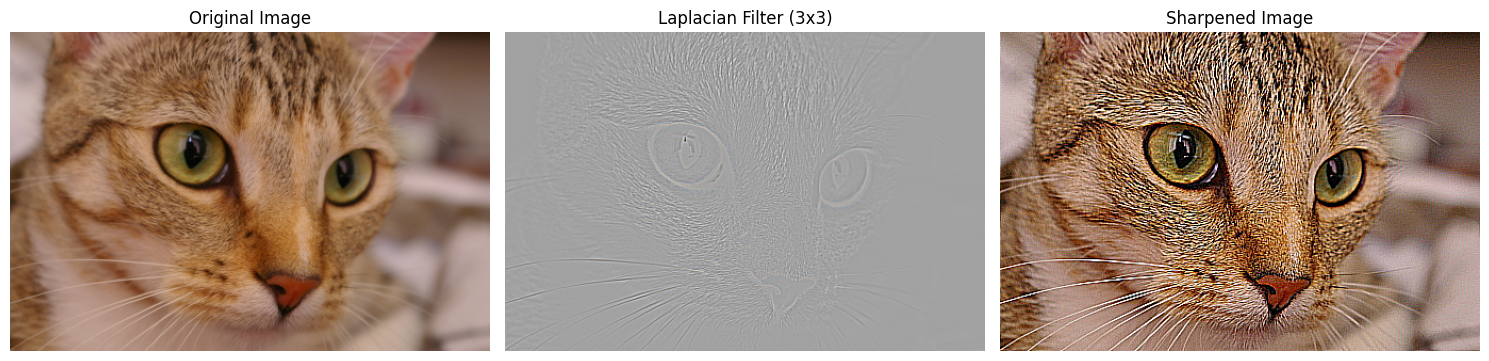

In [4]:
# Read the image
image = cv2.imread('images/chelsea.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert image to float32
image_float = image.astype(np.float32) / 255.0

# Apply the 3x3 Laplacian filter
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

# Sharpen the image
sharpened = np.clip(image_float - laplacian, 0, 1)

# Normalize the Laplacian to [0, 1] for display
laplacian_display = cv2.normalize(laplacian, None, 0, 1, cv2.NORM_MINMAX)

# Plot original, Laplacian, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(laplacian_display)
ax[1].set_title("Laplacian Filter (3x3)")
ax[1].axis("off")
ax[2].imshow(sharpened)
ax[2].set_title("Sharpened Image")
ax[2].axis("off")
plt.tight_layout()
plt.show()